
## 1. Setup

Run the following cell once. It imports QUA and loads the supplied configuration.

In [1]:
from qm.qua import *
from qm.octave import *
from configuration import *
from iqcc_cloud_client import IQCC_Cloud
import numpy as np 
import matplotlib.pyplot as plt 
from importlib import reload
print("Configuration loaded.")


2026-10-23 12:02:16,876 - qm - INFO     - Starting session: 1a47addf-917e-48c6-aa51-ca280de8ca11
Configuration loaded.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def plot_adc(data):
    """
    Plot raw ADC values as a function of time.

    Parameters
    ----------
    data : dict
        QUA execution results containing 'raw_adc'.
    """
    adc_data = np.array(data["raw_adc"])

    adc_values = adc_data[:]

    plt.figure(figsize=(10, 4))
    plt.plot(adc_values)

    plt.xlabel("Time (ns)")
    plt.ylabel("ADC value (a.u.)")
    plt.title("Raw ADC Signal")
    plt.grid(True)
    plt.show()


# Part I — Basic QUA Programming

In this part you will learn the basic structure of a QUA experiment: **operations, configuration, timing, loops, measurements, and stream processing**.

A useful picture is

$\boxed{
\text{QUA program}
\rightarrow
\text{OPX}
\rightarrow
\text{electrical pulses}
}$

The supplied configuration defines the available elements and operations. We will mainly use `qe10` for basic pulse-generation examples and `qe1` when introducing measurement and stream processing.


## 1. Configuration: what can QUA control?

The **configuration** describes the physical control system: the available elements, their hardware connections, pulses, waveforms, intermediate frequencies, RF up/downconversion settings, and measurement parameters.

Rather than treating the configuration as a black box, you will inspect it throughout this lab. Open `configuration.py` alongside this notebook and use it to answer the questions below.

A useful hierarchy to keep in mind is

$$
\boxed{\text{element} \rightarrow \text{operation} \rightarrow \text{pulse} \rightarrow \text{waveform}}
$$

For RF elements, also inspect the corresponding Octave RF input/output settings.


### Exercise 1 — Inspect the configuration

<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>

Using `configuration.py`, answer the following.

1. Which operations are available for `qe1` and for `qe10`?
2. For `qe1`, follow the `"readout"` operation to its pulse definition. What is the pulse length and which waveform is used?
3. What is the configured intermediate frequency of `qe1`?
4. Which Octave RF output is connected to `qe1`?
5. Find the **LO frequency** associated with this RF output. Do not use a value given elsewhere in the notebook.
6. Which Octave RF input receives the signal returning from `qe1`?

Use the code cell below to inspect the relevant dictionaries, and write your answers as comments or additional Markdown.


In [3]:
# Inspect the configuration here.
print("qe1:")
print(config["elements"]["qe1"])

print("\nqe10:")
print(config["elements"]["qe10"])

# Continue inspecting config["pulses"], config["waveforms"],
# and config["octaves"] as needed.

# ANSWERS:
# 1. qe1: {'cw': 'const', 'readout': 'readout_pulse'}, qe10: {'cw': 'const_single', 'readout': 'readout_pulse_raw'}
# 2. qe1 readout: 'readout_pulse'. "length": 2000, "waveforms": cos
# 3. intermediate_frequency: 10000000.0
# 4. port 1
# 5. 5e9 [Hz]
# 6. port 1



qe1:
{'RF_inputs': {'port': ('oct1', 1)}, 'RF_outputs': {'port': ('oct1', 1)}, 'intermediate_frequency': 10000000.0, 'operations': {'cw': 'const', 'readout': 'readout_pulse'}, 'digitalInputs': {'switch': {'port': ('con1', 1), 'delay': 87, 'buffer': 15}}, 'time_of_flight': 200, 'smearing': 0}

qe10:
{'singleInput': {'port': ('con1', 10)}, 'outputs': {'output1': ('con1', 1)}, 'intermediate_frequency': 10000000.0, 'operations': {'cw': 'const_single', 'readout': 'readout_pulse_raw'}, 'time_of_flight': 200, 'smearing': 0}



## 2. Your first QUA program

A QUA program is defined inside a `program()` context. The command

```python
play(operation, element)
```

schedules an operation on an element.


In [4]:
with program() as first_program:
    adc_st = declare_stream(adc_trace=True)
    
    
    play("cw", "qe11")
    
    
    measure("readout", "qe10", adc_stream=adc_st)
    with stream_processing():
        adc_st.input1().save("raw_adc")

C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\4019588451.py:2: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead, and do not use the adc_trace argument, as it is no longer needed
  adc_st = declare_stream(adc_trace=True)



The program above contains one instruction: play the configured `cw` pulse on `qe11`.

Notice that defining the QUA program does **not** execute it. The program must subsequently be sent to the OPX.


In [5]:
import configuration
reload(configuration)
from configuration import *
qm = IQCC_Cloud("edusetup")

job = qm.execute(first_program, qua_config=config)    
    

c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\qm\program\_qua_config_schema.py:261: RemovedInMarshmallow4Warning: The `context` parameter is deprecated and will be removed in marshmallow 4.0. Use `contextvars.ContextVar` to pass context instead.
  QuaConfigSchema(


[12:02:43] QUA program submitted to edusetup (id = 08ff03b8-25c5-45fd-a1fc-55b310453d4a)           ]8;id=14934505;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934506;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934512;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934513;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:02:46] Execution finished                                                                      ]8;id=14934519;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

Inspect the play() operation output

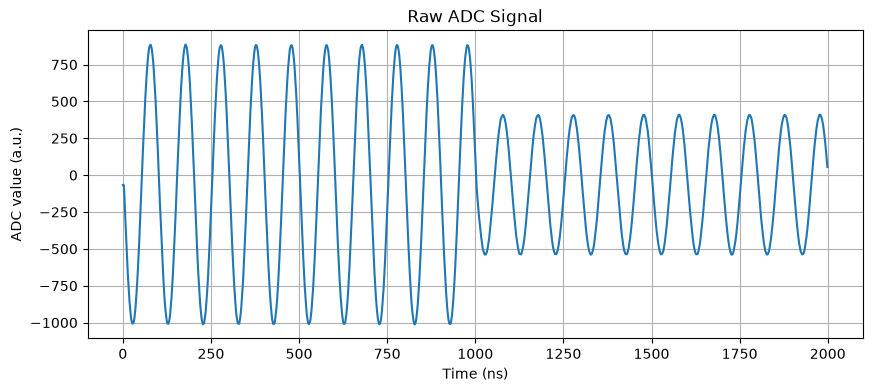

In [6]:
data = job["result"]
plot_adc(data)

<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>


From the raw ADC signal and configuration: 
1. What is the duration of the readout pulse?
2. What is the duration of the cw pulse? 
3. What is the frequency of the cw pulse?


In [7]:
# ANSWERS:
# 1. 2000 [ns]
# 2. 1000 [ns]
# 3. 10e6 [Hz]


## 3. Timing: `wait()` and `align()`

Each QUA element has its own timeline. Operations on the **same element** are executed sequentially.

The command

```python
wait(t, "qe11")
```

inserts a delay on the timeline of `qe11`.

For the OPX+ used in this experiment, QUA timing commands use clock cycles of $4\,\mathrm{ns}$. Therefore,

$
t=25 \quad\Rightarrow\quad 100\,\mathrm{ns}.
$

Pulse lengths in the configuration, however, are specified directly in nanoseconds.


In [8]:
delay_ns = 100
delay_cycles = delay_ns // 4

with program() as timing_program:
    adc_st = declare_stream(adc_trace=True)
    play("cw", "qe11")
    wait(delay_cycles, "qe11")
    play("cw", "qe12")
    play("cw", "qe11")
    

    measure("readout", "qe10", adc_stream=adc_st)
    with stream_processing():
        adc_st.input1().save("raw_adc")

C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\3856955106.py:5: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead, and do not use the adc_trace argument, as it is no longer needed
  adc_st = declare_stream(adc_trace=True)


**Execute**

[12:03:09] QUA program submitted to edusetup (id = 3bd7e166-6228-4eeb-b430-4073f587fc91)           ]8;id=14934525;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934526;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934531;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934532;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:03:12] Execution finished                                                                      ]8;id=14934537;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

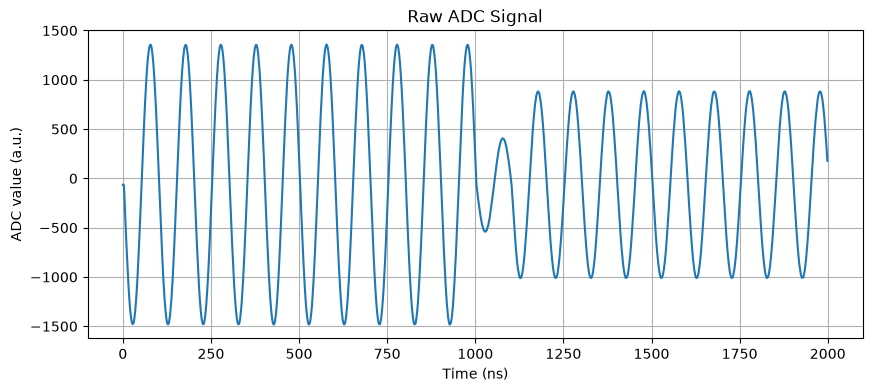

In [9]:
import configuration
reload(configuration)
from configuration import *

qm = IQCC_Cloud("edusetup")

job = qm.execute(timing_program, qua_config=config)   

data = job["result"] 

plot_adc(data)
    


Different elements have independent timelines, so commands on different elements may execute simultaneously. `align()` synchronizes their timelines before continuing.

For example:

```python
play("cw", "qe11")
play("cw", "qe12")
align("qe11", "qe12")
```

The two elements execute independently until the `align()` command; execution after it starts only after both timelines have reached the synchronization point.


<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>


### Exercise 2 — Timing

**1.Modify** `timing_program` so that the "qe12" pulse is executed after the first "qe11" pulse.

In [10]:
# Write your modified program here.
with program() as timing_exercise:
    
    adc_st = declare_stream(adc_trace=True)
    
    play("cw", "qe11")
    align("qe11", "qe12")
    play("cw", "qe12")
    wait(250, "qe11")
    play("cw", "qe11")

    measure("readout", "qe10", adc_stream=adc_st)
    with stream_processing():
        adc_st.input1().save("raw_adc")


C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\3809049623.py:4: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead, and do not use the adc_trace argument, as it is no longer needed
  adc_st = declare_stream(adc_trace=True)


**2. Run and plot** your program results:

[12:03:28] QUA program submitted to edusetup (id = 0addfe6e-0475-45c2-8056-601ce0b0e4bc)           ]8;id=14934543;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934544;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934549;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934550;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:03:31] Execution finished                                                                      ]8;id=14934555;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

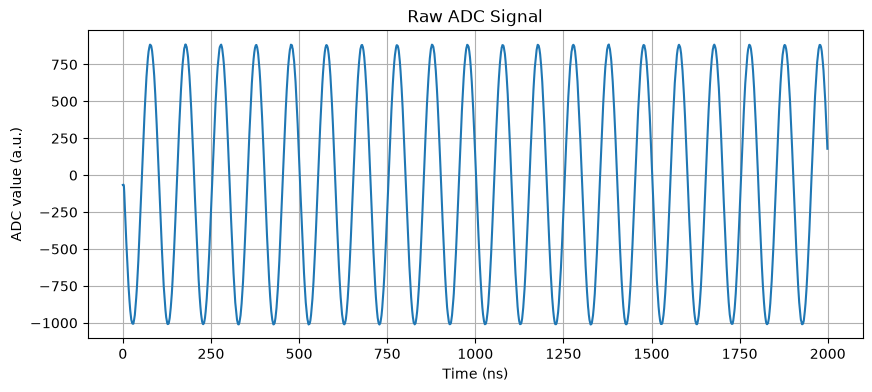

In [11]:
import configuration
reload(configuration)
from configuration import *
qm = IQCC_Cloud("edusetup")

job = qm.execute(timing_exercise, qua_config=config)   

data = job["result"] 

plot_adc(data)

**3. Explain** the difference between the `timing_program` and your program.

In [12]:
# ANSWER: In the timing_program, the second "play" command for "qe11" is executed after a wait of 25 cycles. In our script we aligned the two elements so they come one after the other, and the wait time of qe11 is 250 cycles, which is the length of qe12.


## 4. QUA variables and loops

Experiments usually require many repetitions. QUA provides variables and loops that execute directly on the real-time controller.

A QUA variable is declared using

```python
n = declare(int)
```

and a QUA loop can be written using `for_()`.


In [13]:
n_repetitions = 10

with program() as loop_program:
    
    n = declare(int)

    with for_(n, 0, n < n_repetitions, n + 1):
        play("cw", "qe11", duration=25)
        wait(50, "qe11")   # 1 us for OPX+
    
    
    measure("readout", "qe10", adc_stream=adc_st)
    with stream_processing():
        adc_st.input1().save("raw_adc")

[12:03:43] QUA program submitted to edusetup (id = 66538190-c055-4659-88c0-e157d26d79e2)           ]8;id=14934561;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934562;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934567;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934568;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:03:47] Execution finished                                                                      ]8;id=14934573;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

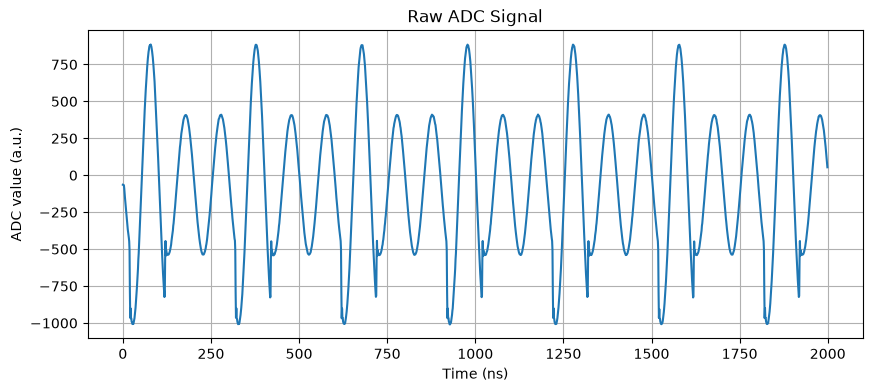

In [14]:
import configuration
reload(configuration)
from configuration import *
qm = IQCC_Cloud("edusetup")

job = qm.execute(loop_program, qua_config=config)   

data = job["result"] 

plot_adc(data)


This differs from a Python loop. Python constructs the experiment on the host PC, whereas a QUA `for_()` loop is compiled and executed by the OPX controller.

QUA also provides

```python
with infinite_loop_():
    ...
```

for operations that should repeat continuously until the running job is stopped.


### Exercise 3 — Repetition and alignment

<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>

**Important** - In order to see all 100 loops in the plot:
1. Go to `pulses` in the configuration file
2. Find `readout_pulse_raw` 
3. Change the `length` to be large enough to read all 100 loops

Write a QUA program that repeats the following sequence 100 times:

1. Play `"cw"` on `qe11`.
2. Wait $2\,\mu\mathrm{s}$ on `qe11`.
3. Synchronize `qe11` and `qe12`.
4. Play `"cw"` on `qe12`.

Which QUA operation is required to synchronize the two elements?


In [15]:
with program() as loop_exercise:
    n = declare(int)

    with for_(n, 0, n < n_repetitions, n + 1):
        play("cw", "qe11")
        wait(500, "qe11")
        align("qe11", "qe12")
        play("cw", "qe12")
    
    measure("readout", "qe10", adc_stream=adc_st)
    with stream_processing():
        adc_st.input1().save("raw_adc")

[12:04:22] QUA program submitted to edusetup (id = c0454dab-6c7a-4a0b-b3bb-fe279a313881)           ]8;id=14934597;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934598;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934603;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934604;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:04:25] Execution finished                                                                      ]8;id=14934609;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

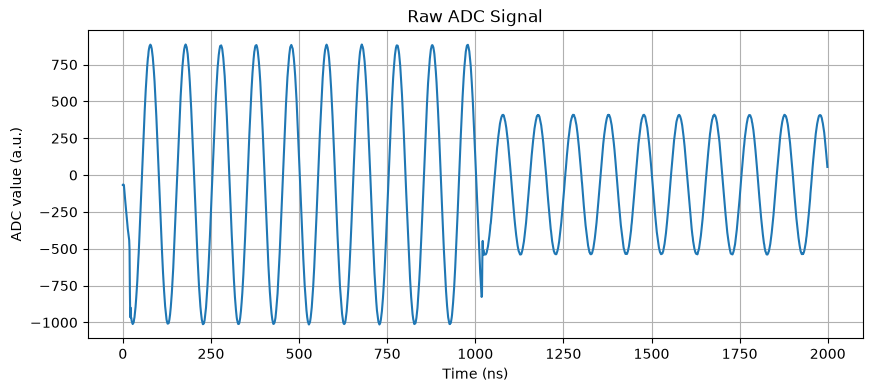

In [18]:
import configuration
reload(configuration)
from configuration import *
qm = IQCC_Cloud("edusetup")

job = qm.execute(loop_exercise, qua_config=config)   

data = job["result"] 

plot_adc(data)

## 5. Amplitude and frequency sweeps

The amplitude of an operation can be scaled using

```python
play("cw" * amp(a), "qe11")
```

and the intermediate frequency of an element can be changed during a QUA program using

```python
update_frequency("qe11", f)
```


### Exercise 4 — Amplitude and frequency sweeps

<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>

**a.** Write the relevant QUA code to sweep the amplitude of the `"cw"` pulse on `qe11` from 0.1 to 1.0 in steps of 0.1, playing the pulse once at each amplitude.

**b.** Inspect `configuration.py` and find the intermediate frequency initially assigned to `qe11`. Record it below.

**c.** Write the relevant QUA code to sweep the intermediate frequency of `qe11` from $40\,\mathrm{MHz}$ to $60\,\mathrm{MHz}$ in steps of $1\,\mathrm{MHz}$, playing `"cw"` once at each frequency.

**d.** Does `update_frequency()` change the LO frequency or the IF? Briefly explain.


In [19]:
# ANSWER HERE

# Initial IF of qe11: IF=10e6


# (a) Amplitude sweep:
a = declare(float)
with for_(a, 0.1, a < 1.1, a + 0.1):
    play("cw"*amp(a), "qe11")
    wait(250, "qe11")
    
# (c) Frequency sweep:
f = declare(float)
with for_(f, 40e6, f < 61e6, f + 1e6):
    update_frequency("qe11", f)
    play("cw", "qe11")
    wait(250, "qe11")

# (d) Explanation: That changes the IF frequency


NoScopeFoundException: No program scope found


## 6. Measurement and streams

`play()` generates an output pulse. `measure()` generates a measurement pulse **and acquires an input signal**.

The supplied configuration defines the operation

```python
"readout": "readout_pulse_raw"
```

for `qe10`.

A stream is used to transfer data generated during real-time execution to the result-processing stage. For example, `adc_trace=True` creates a stream containing raw ADC samples.


In [20]:
with program() as single_measurement:
    adc_st = declare_stream(adc_trace=True)
    play("cw", "qe11", duration=25)
    measure("readout", "qe10", adc_stream=adc_st)

    with stream_processing():
        adc_st.input1().save("raw_adc")
      


C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\229783425.py:2: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead, and do not use the adc_trace argument, as it is no longer needed
  adc_st = declare_stream(adc_trace=True)


[12:08:25] QUA program submitted to edusetup (id = 0ab5ac90-d2d2-4c5b-ac46-8103339697e0)           ]8;id=14934615;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934616;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934621;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934622;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:08:29] Execution finished                                                                      ]8;id=14934627;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

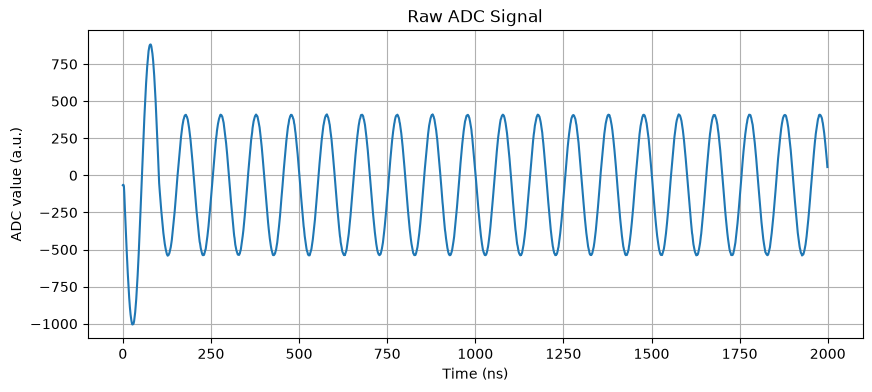

In [21]:
import configuration
reload(configuration)
from configuration import *
qm = IQCC_Cloud("edusetup")
job = qm.execute(single_measurement, qua_config=config) 
data = job["result"]
plot_adc(data)


Here the sequence is

$
\boxed{
\texttt{measure()}
\rightarrow
\text{ADC samples}
\rightarrow
\text{stream}
\rightarrow
\texttt{stream\_processing()}
\rightarrow
\text{saved result}
}
$

`stream_processing()` specifies what should be done with the collected data before it is returned to the PC.



## 7. Averaging with stream processing

A common experiment repeats the same measurement many times and averages the results. Averaging reduces uncorrelated noise without requiring all individual traces to be transferred to the PC.


Run this program once with `play("cw", "qe10")` and once with `play("cw", "qe11")` - **Explain** the difference between the measurement results.

In [ ]:
# Answer Here - For play qe11 we can see the measurement of it by qe10, they are different elements so no interference occurs. For qe10, the two operations (play, measure) cannot run at the same time, so the measurement is done after the play and shows 0.

In [22]:
n_avg = 1000

with program() as averaged_adc:
    n = declare(int)
    adc_st = declare_stream(adc_trace=True)

    with for_(n, 0, n < n_avg, n + 1):
        play("cw", "qe11") # Run once with qe10 and once with qe11
        measure("readout", "qe10", adc_stream=adc_st)
        wait(2000, "qe10")

    with stream_processing():
        adc_st.input1().average().save("raw_adc")


C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\2339623412.py:5: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead, and do not use the adc_trace argument, as it is no longer needed
  adc_st = declare_stream(adc_trace=True)


[12:09:36] QUA program submitted to edusetup (id = faf13f36-05c3-47cd-a4ef-4ccaed8b3d5e)           ]8;id=14934633;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934634;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14934639;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14934640;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[12:09:40] Execution finished                                                                      ]8;id=14934645;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

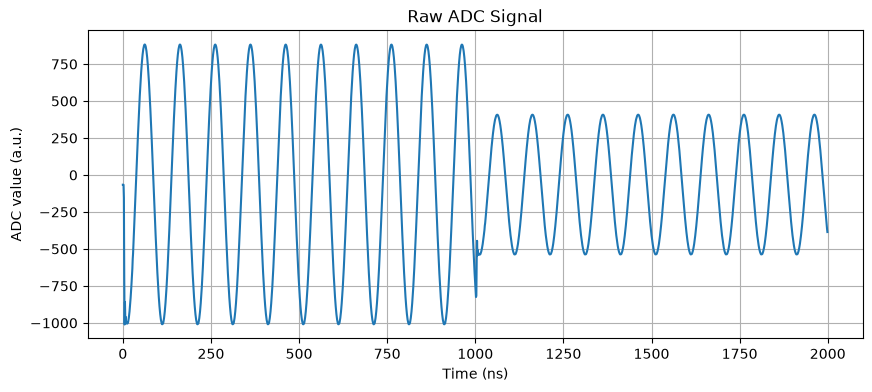

In [23]:
import configuration
reload(configuration)
from configuration import *
qm = IQCC_Cloud("edusetup")
job = qm.execute(averaged_adc, qua_config=config) 
data = job["result"]
plot_adc(data)


The important distinction is:

- `measure()` and the QUA loop run in real time on the OPX.
- `stream_processing()` defines how the resulting data are processed and returned.
- `.average()` averages corresponding ADC samples over all repetitions.

This allows a large number of measurements to be reduced to one averaged trace.


<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>

### Exercise 5 — Amplitude Sweep and Averaging

Write a QUA program that:

1. Sweeps the amplitude of the `"readout"` pulse on `qe11`
   from 0.1 to 1.0 in steps of 0.1.
2. Records the raw ADC trace from input 2 at each amplitude.
3. Repeats the entire amplitude sweep 100 times.
4. Uses stream processing to average the ADC traces over
   the 100 repetitions for each amplitude.
5. Saves the averaged ADC traces under the name `"adc_avg"`.


**Hint:** Use nested `for_` loops and the stream-processing
operations `buffer()` and `average()`.

In [ ]:
n_avg = 100

with program() as final_exercise:
    # Your code here
    pass


## 8. Summary and in-lab submission

The basic structure of a QUA experiment is

$$
\boxed{
\begin{array}{c}
\text{Configuration: define elements and available operations}\\
\downarrow\\
\text{QUA program: play, wait, align, measure, loops}\\
\downarrow\\
\text{Real-time execution on the OPX}\\
\downarrow\\
\text{Stream processing and results}
\end{array}}
$$

**All highlighted questions and code cells in Part I must be completed in this notebook during the lab.**

The next part connects these concepts to the microwave signal chain and the role of frequency up- and downconversion.


# Part II — Up/Down Conversion and IQ Modulation

In Part I, you programmed pulses and changed their **intermediate frequency (IF)**. The physical resonator, however, is driven and measured using microwave signals at a much higher **RF frequency**.

The purpose of this part is to understand the basic signal path used in the setup:

$$
\boxed{\text{OPX} \rightarrow \text{Octave} \rightarrow \text{resonator} \rightarrow \text{Octave} \rightarrow \text{OPX}}
$$

The **OPX** generates and processes the intermediate-frequency signals, while the **Octave** converts between IF and microwave RF using a local oscillator (LO).

All highlighted questions in Part II should be answered in this notebook during the lab.

## 9. From the OPX to the resonator: upconversion

The OPX generates two quadratures at the intermediate frequency:

$$
I(t)=A\cos(\omega_{\mathrm{IF}}t), \qquad Q(t)=A\sin(\omega_{\mathrm{IF}}t).
$$

These two signals are sent to the **Octave**. The Octave contains an IQ mixer and a local oscillator at frequency $\omega_{\mathrm{LO}}$. In the simple ideal picture,

$$
V_{\mathrm{RF}}(t)=I(t)\cos(\omega_{\mathrm{LO}}t)-Q(t)\sin(\omega_{\mathrm{LO}}t).
$$

Substituting $I(t)$ and $Q(t)$ and using $\cos a\cos b-\sin a\sin b=\cos(a+b)$ gives

$$
\boxed{V_{\mathrm{RF}}(t)=A\cos[(\omega_{\mathrm{LO}}+\omega_{\mathrm{IF}})t]}
$$

and therefore

$$
\boxed{f_{\mathrm{RF}}=f_{\mathrm{LO}}+f_{\mathrm{IF}}.}
$$

The important idea is that the OPX does **not** have to directly generate the microwave carrier. It generates the lower-frequency $I$ and $Q$ signals, while the Octave translates them to the required microwave frequency.

$$
\boxed{\text{OPX: }I,Q\text{ at IF} \rightarrow \text{Octave: IQ mixer + LO} \rightarrow \text{RF} \rightarrow \text{resonator}}
$$

### Exercise 6 — Follow the outgoing signal

<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>

Inspect `configuration.py` and answer:

1. What is the configured intermediate frequency of `qe1`?
2. Which Octave RF output is connected to `qe1`?
3. What is the LO frequency of this output?
4. Using $f_{\mathrm{RF}}=f_{\mathrm{LO}}+f_{\mathrm{IF}}$, calculate the microwave frequency sent to the resonator for the configured IF.
5. If the program executes `update_frequency("qe1", 50e6)`, which quantity changes: the IF or the LO?
6. What RF frequency is then sent to the resonator?
7. In your own words, what is the role of the OPX and what is the role of the Octave in generating the microwave signal?

In [24]:
# Inspect configuration.py and write your answers below.

# 1. IF = 10e6
# 2. Octave RF output = port 1
# 3. LO = 5e9
# 4. RF frequency = 5.01e9
# 5. That changes the IF frequency
# 6. New RF frequency = 5.05e9
# 7. The OPX generates the pulse at low frequency and the Octave upconverts it to a high RF frequency using the LO, higher than the OPX can achieve alone.

## 10. From the resonator back to the OPX: downconversion

After interacting with the resonator, the returning signal is still a microwave RF signal:

$$
V_{\mathrm{RF}}(t)=A\cos(\omega_{\mathrm{RF}}t+\phi).
$$

The amplitude $A$ and phase $\phi$ can both contain information about the resonator.

The returning signal enters the **Octave**, where it is mixed with the LO. After filtering out the high-frequency mixing product, the remaining signal is at

$$
\boxed{\omega_{\mathrm{IF}}=\omega_{\mathrm{RF}}-\omega_{\mathrm{LO}}.}
$$

Thus,

$$
\boxed{\text{RF from resonator} \rightarrow \text{Octave + LO} \rightarrow \text{IF} \rightarrow \text{OPX}}
$$

The OPX demodulates the IF signal into two quadratures. In the simplest picture,

$$
\boxed{I\propto A\cos\phi, \qquad Q\propto A\sin\phi.}
$$

Keeping both quadratures preserves amplitude and phase:

$$
\boxed{A\propto\sqrt{I^2+Q^2}}, \qquad
\boxed{\phi=\operatorname{atan2}(Q,I)}.
$$

This is the basic idea of IQ demodulation: instead of keeping only one real-valued signal, we retain the amplitude-and-phase information needed to characterize the resonator.

$$
\boxed{\text{OPX} \rightarrow \text{Octave} \rightarrow \text{resonator} \rightarrow \text{Octave} \rightarrow \text{OPX}}
$$

### Example — Measuring the I and Q quadratures in QUA

The `measure()` operation can return **demodulated I and Q values**, rather than a raw ADC trace. First declare two `fixed` variables and two streams. The two `dual_demod.full(...)` expressions extract the quadratures using the integration weights defined in `configuration.py`. Save the results to streams so they can be retrieved in Python.

The example below measures **one point at the configured IF**. In Part III, you will extend this idea to measure I and Q at many frequencies.

In [25]:
with program() as iq_example:
    I = declare(fixed)
    Q = declare(fixed)
    I_st = declare_stream()
    Q_st = declare_stream()

    measure(
        "readout", "qe1", None,
        dual_demod.full("cos", "sin", I),
        dual_demod.full("minus_sin", "cos", Q),
    )
    save(I, I_st)
    save(Q, Q_st)

    with stream_processing():
        I_st.save("I")
        Q_st.save("Q")


C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\1341742490.py:4: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead
  I_st = declare_stream()
C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\1341742490.py:5: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead
  Q_st = declare_stream()
C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\1341742490.py:7: DeprecationWarning: Putting `None` to indicate no adc streaming is no longer required, please remove it from the measure call
  measure(


### Exercise 7 — Follow the returning signal

<div style="border: 2px solid #d39e00; background-color: #fff3cd; color: #212529; padding: 10px; border-radius: 6px;">
<b>✎ ANSWER IN THE NOTEBOOK — part of the in-lab submission</b>
</div>

Inspect `configuration.py` and answer:

1. Which Octave RF input receives the signal returning from `qe1`?
2. What LO frequency is used for this input?
3. Suppose the returning microwave signal has frequency $f_{\mathrm{RF}}$. What IF reaches the OPX after downconversion?
4. What information is contained in $I$ and $Q$?
5. Why is it useful to measure both $I$ and $Q$ when characterizing a resonator?
6. Complete the signal sequence below with the relevant frequencies or quantities:

$$
\text{OPX}
\xrightarrow{\quad ? \quad}
\text{Octave}
\xrightarrow{\quad ? \quad}
\text{resonator}
\xrightarrow{\quad ? \quad}
\text{Octave}
\xrightarrow{\quad ? \quad}
\text{OPX}.
$$

Your answer should identify where the IF, LO/RF, and measured $I,Q$ enter the sequence.

In [26]:
# ANSWERS:

# 1. port 1
# 2. 5e9
# 3. IF = 10e6
# 4. I and Q samples provide the amplitude and phase information of the returned signal from the resonator, which is dependent on the qubit state. 
# 5. For different states the signal will have different amplitude and phase - represented by I,Q. Using only one of them provides less information.
# 6. Signal sequence: IQ-IF -> RF -> RF -> IF -> IQ

# Part III — Classical Resonator Spectroscopy

Your goal is to determine the resonance frequency of a **classical microwave resonator**.

Unlike Parts I and II, you are **not expected to complete the data analysis during the lab**. During the lab, your main goal is to design, write, debug, and run a proper spectroscopy experiment and leave with the data required to determine the resonance frequency.

### During the lab
You should:
- determine the relevant configuration parameters;
- choose an appropriate IF sweep;
- write the QUA experiment;
- acquire $I$ and $Q$ as functions of frequency;
- verify that the returned arrays have the expected size;
- **save the frequency array and measured data for later analysis**.

### At home
Process the saved data, plot the resonator response, and extract the resonance frequency.


## 11. Design the spectroscopy experiment

Before writing code, decide what the experiment must do.

Your program should:

1. Inspect the configuration and determine the LO used by the resonator element.
2. Choose a suitable range of intermediate frequencies to scan.
3. At every IF, use `update_frequency()` to change the measurement frequency.
4. Apply the configured `"readout"` measurement pulse.
5. Demodulate the response to obtain $I$ and $Q$.
6. Repeat the measurement enough times to reduce noise.
7. Average the response independently at every frequency point.
8. Return one averaged $I$ value and one averaged $Q$ value for each IF.

Remember that the physical microwave frequency follows from the LO and IF according to the sideband convention established in Part II.

The purpose here is not merely to make the program run: the returned data must contain enough frequency-dependent information to locate the resonator response later.


### Exercise 8 — Write and run the QUA spectroscopy experiment

<div style="border: 2px solid #0b7285; background-color: #e7f5ff; color: #212529; padding: 10px; border-radius: 6px;">
<b>LAB GOAL — complete the experiment and save the acquired data before leaving.</b>
</div>

Construct the spectroscopy program below. Use the programs from Part I and the signal-chain discussion from Part II as references.

Before running it, check:

- What is the configured LO?
- How will stream processing preserve the frequency axis while averaging over repetitions?

You may ask the instructor to check your sweep range before executing the experiment.


In [75]:
# -----------------------------
# Experimental parameters
# -----------------------------
n_avg = 1000

# Choose the IF sweep used for the spectroscopy experiment.
f_min = -400e6
f_max = 400e6
df = 0.25e6
frequencies = np.arange(f_min, f_max + df/2, df, dtype=int)

# -----------------------------
# QUA program
# -----------------------------
with program() as resonator_spectroscopy:

    # Declare the QUA variables and streams you need.
    # Your code here.
    I = declare(fixed)
    Q = declare(fixed)
    I_st = declare_stream()
    Q_st = declare_stream()
    f = declare(int)
    n = declare(int)

    with for_(f, f_min, f <= f_max, f + df):
        update_frequency("qe1", f)      
        with for_(n, 0, n < n_avg, n + 1):
            measure("readout", "qe1", None,
                dual_demod.full("cos", "sin", I),
                dual_demod.full("minus_sin", "cos", Q),
            )
            save(I, I_st)
            save(Q, Q_st)
            wait(1000, 'qe1')  # Wait for the resonator to relax before the next measurement.
        
            
    with stream_processing():
        I_st.buffer(n_avg).map(FUNCTIONS.average()).buffer(len(frequencies)).save("I")
        Q_st.buffer(n_avg).map(FUNCTIONS.average()).buffer(len(frequencies)).save("Q")

    # Build:
    #   repetitions
    #       -> IF sweep
    #           -> update_frequency(...)
    #           -> measure(...) with demodulation
    #           -> save I and Q
    #
    # Then use stream_processing() so the returned I and Q
    # contain one averaged value per frequency.
    pass


C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\3764855719.py:21: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead
  I_st = declare_stream()
C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\3764855719.py:22: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead
  Q_st = declare_stream()
C:\Users\mor14\AppData\Local\Temp\ipykernel_27488\3764855719.py:29: DeprecationWarning: Putting `None` to indicate no adc streaming is no longer required, please remove it from the measure call
  measure("readout", "qe1", None,


## 12. Run the experiment and save the data

Once your program is complete, execute it and retrieve the results.

Before leaving the lab, verify that:

- the experiment ran successfully;
- the returned $I$ and $Q$ arrays contain one value per swept frequency;
- the data are not obviously empty or constant because of a programming error;
- you saved `frequencies`, `I`, and `Q` in a file that you can process later.

**Do not spend lab time performing the full resonator analysis unless you have already completed Parts I and II.**

At home, use the saved data to construct the RF-frequency axis, calculate the resonator response, and determine the resonance frequency.


In [76]:
# Execute your completed experiment.
import configuration
reload(configuration)
from configuration import *

qc = IQCC_Cloud("edusetup")
result = qc.execute(resonator_spectroscopy, qua_config=config)

data = result["result"]

I = np.asarray(data["I"])
Q = np.asarray(data["Q"])

print("Number of frequency points:", len(frequencies))
print("I shape:", I.shape)
print("Q shape:", Q.shape)

# Save everything needed for the at-home analysis.
np.savez(
    "resonator_spectroscopy_data.npz",
    frequencies=frequencies,
    I=I,
    Q=Q,
)

print("Saved: resonator_spectroscopy_data.npz")


c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\qm\program\_qua_config_schema.py:261: RemovedInMarshmallow4Warning: The `context` parameter is deprecated and will be removed in marshmallow 4.0. Use `contextvars.ContextVar` to pass context instead.
  QuaConfigSchema(


[16:10:38] QUA program submitted to edusetup (id = 402bd408-3df9-4685-a831-30239826ffc1)           ]8;id=14935083;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14935084;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=14935089;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=14935090;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[16:11:01] Execution finished                                                                      ]8;id=14935095;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py

## 13. What you submit / take home

### Submit by the end of the lab
Your notebook should contain completed answers and code for **Parts I and II**. All required response locations are highlighted in yellow.

### Complete after the lab
For **Part III**, take home the saved spectroscopy data. Your later analysis should use the measured $I,Q$ response versus frequency to determine the classical resonator's resonance frequency.

The complete experimental chain is

$$
\boxed{
\text{configuration}
\rightarrow
\text{IF waveform}
\rightarrow
\text{IQ upconversion}
\rightarrow
\text{resonator}
\rightarrow
\text{IQ downconversion}
\rightarrow
\text{ADC/demodulation}
\rightarrow
I(f),Q(f)
}
$$

The central experimental task in Part III is therefore to leave the laboratory with a valid measurement of $I(f)$ and $Q(f)$, not with a finished plot.
